# TP 2 – Bagging and random forests – Solutions

Second of five practical sessions (1: protocol, 2: bagging, 3: boosting, 4 and 5: PAC-Bayes). At the end of TP 1, a majority vote of trees learned on bootstrap samples was much better than a single tree. In this session we understand why. We first measure the instability of decision trees and decompose their error into bias and variance; we then implement bagging, use its out-of-bag error, and check that bagging reduces the variance but not the bias, so that it helps unstable models only. Finally, random forests decorrelate the trees, and we observe the trade-off between the accuracy of the voters and their diversity. We end by reproducing the "puzzling experiment" that opens Part IV of the lecture notes with the notation of the PAC-Bayesian analysis of majority votes.

**Data.** `wdbc`, `pima`, `australian` and `spambase` ($4597$ e-mails, $57$ features), loaded with `load(name)` of `common/tptools.py`, labels in $\{-1,+1\}$, with $70\%/30\%$ stratified training/test splits (`random_state=seed`); and the regression problem $Y=\sin(2\pi X)+\varepsilon$, $X$ uniform on $[0,1]$, $\varepsilon\sim\mathcal N(0,0.3^2)$. The protocol of TP 1 applies: the test set is used only to report errors. The file `tp2_starter.py` contains the skeletons.

> **Good practice.** Store the predictions of all the base models in a $B\times n_{\text{test}}$ matrix `V` of $\pm1$ values: the vote of the first $B$ models is `np.sign(np.cumsum(V, 0))` (decide what to do with ties), the mean error of a model is `np.mean(V != y)`, and many quantities of this session are one line of `numpy` away.

## Setup

In [2]:
import os, sys, time, warnings
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
warnings.filterwarnings("ignore")

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
sys.path.insert(0, os.path.join(HERE, "..", "common"))
from tptools import load, show_table as _show_rows

C1, C2, C3, C4, C5, GREY = "#1f5f99", "#c8553d", "#2a9d8f", "#e9a13b", "#6c4f9c", "#8c8c8c"
plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "savefig.bbox": "tight"})


plt.rcParams["figure.dpi"] = 120

# column headers of the tables
HEADERS = {
    'p1_instability': ['depth', 'test error of a tree', 'disagreement between two trees'],
    'p1_biasvar': ['depth $D$', 'bias$^2$', 'variance', 'bias$^2$+variance+$\\sigma^2$'],
    'p2_bootstrap': ['$m$', 'simulated proportion', '$1-(1-\\frac1m)^m$', '$1-e^{-1}$'],
    'p2_bagging': ['data', 'one full tree', 'mean bagged tree', 'vote ($B=200$)', 'OOB error', '`BaggingClassifier`'],
    'p3_biasvar_bag': ['depth', 'model', 'bias$^2$', 'variance', 'bias$^2$+variance+$\\sigma^2$'],
    'p3_stable': ['base model', '`pima` – alone', '`pima` – bagged', '`spambase` – alone', '`spambase` – bagged'],
    'p4_rf': ['data', '$m_{\\text{try}}$', 'mean error of a tree', 'mean disagreement', 'error of the vote'],
    'p4_sklearn': ['data', 'tuned single tree (test)', 'forest, OOB error', 'forest, test error'],
    'p4_digits': ['vote (test)', 'Gibbs risk $\\widehat{R}(G_Q)$', 'errors of the trees', 'joint error $\\hat e(Q)$', 'disagreement $\\hat d(Q)$', '$\\hat e+\\hat d/2$'],
    'p5_bagvar': ['$B$', 'measured variance', '$\\hat\\rho\\sigma^2+(1-\\hat\\rho)\\sigma^2/B$'],
}


TABLES, FIGURES = {}, {}


def keep_table(name, rows):
    """Keep the rows of a table ('a & b & c', math between $) to show it later with show_table(name)."""
    TABLES[name] = rows


def keep_figure(fig, name):
    """Keep a figure to show it later with show_figure(name)."""
    FIGURES[name] = fig
    plt.close(fig)


def show_table(name):
    _show_rows(TABLES[name], HEADERS.get(name))


def show_figure(name):
    from IPython.display import display
    display(FIGURES[name])


def f_true(x):
    return np.sin(2 * np.pi * x)


def split(name, seed):
    X, y = load(name)
    return train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)

ImportError: cannot import name 'show_table' from 'tptools' (/Users/guillaumemetzler/Documents/GuillaumeMetzler.github.io/files/courses/ensemblemethods/tp/tp2/../common/tptools.py)

## Part 1 – Trees are unstable (Sections 8.7 and 10.1)

1.  On `pima` (split `seed=0`), learn two trees on two bootstrap samples of the training set ($m$ indices drawn with replacement) and compute the proportion of test points on which they disagree.\
    Repeat $20$ times, for maximal depths $1$, $2$, $5$ and unlimited.\
    Compare with the test error of a tree.

2.  **Bias and variance.** For the regression problem, draw $R=200$ training samples of size $m=100$, learn a regression tree of maximal depth $D$ on each, and estimate on a regular grid of $[0,1]$ the squared bias $\overline{(\bar f_D(x)-f(x))^2}$ and the variance $\overline{\mathrm{Var}_r\hat f^{(r)}_D(x)}$, where $\bar f_D$ is the average of the $R$ trees and the bar denotes the average over the grid.\
    Plot them for $D\in\{1,\dots,12\}$.\
    Recall why the expected test MSE is $\text{bias}^2+\text{variance}+\sigma^2$.

In [2]:
def part1():
    print("Part 1")
    Xtr, Xte, ytr, yte = split("pima", 0)
    rng = np.random.RandomState(0); rows = []
    for depth in [1, 2, 5, None]:
        dis, er = [], []
        for _ in range(20):
            i1, i2 = rng.randint(0, len(ytr), len(ytr)), rng.randint(0, len(ytr), len(ytr))
            p1 = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xtr[i1], ytr[i1]).predict(Xte)
            p2 = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xtr[i2], ytr[i2]).predict(Xte)
            dis.append(np.mean(p1 != p2)); er.append(np.mean(p1 != yte))
        rows.append(f"{'full' if depth is None else depth} & {np.mean(er):.3f} & {np.mean(dis):.3f}")
    keep_table("p1_instability", rows)
    # bias-variance of regression trees, y = sin(2 pi x) + noise
    rng = np.random.RandomState(1); xs = (np.arange(200) + 0.5) / 200; R, m, sig = 200, 100, 0.3
    depths = list(range(1, 13)); rows = []; B2, V = [], []
    for dpt in depths:
        P = []
        for _ in range(R):
            x = rng.rand(m); yy = f_true(x) + sig * rng.randn(m)
            P.append(DecisionTreeRegressor(max_depth=dpt, random_state=0).fit(x[:, None], yy).predict(xs[:, None]))
        P = np.array(P); b2 = np.mean((P.mean(0) - f_true(xs)) ** 2); v = np.mean(P.var(0)); B2.append(b2); V.append(v)
        rows.append(f"{dpt} & {b2:.4f} & {v:.4f} & {b2 + v + sig ** 2:.4f}")
    keep_table("p1_biasvar", rows)
    fig, ax = plt.subplots(figsize=(4.2, 2.5))
    ax.plot(depths, B2, "o-", ms=3, color=C4, label="bias$^2$"); ax.plot(depths, V, "o-", ms=3, color=C5, label="variance")
    ax.plot(depths, np.array(B2) + np.array(V), "o-", ms=3, color="k", label="bias$^2$ + variance")
    ax.set_yscale("log"); ax.set_xlabel("maximal depth"); ax.set_title("regression tree, $m=100$, $\\sigma=0.3$", fontsize=9)
    ax.legend(fontsize=7)
    fig.tight_layout(); keep_figure(fig, "tp2_biasvar")

In [3]:
part1()

Part 1


### Solution

**1.** Mean test error of a tree and mean disagreement between two trees learned on two bootstrap samples:

In [4]:
show_table("p1_instability")

| depth | test error of a tree | disagreement between two trees |
|:---:|:---:|:---:|
| 1 | 0.272 | 0.117 |
| 2 | 0.241 | 0.126 |
| 5 | 0.266 | 0.224 |
| full | 0.292 | 0.287 |

Two fully grown trees learned from two resamples of the same data disagree on almost $30\%$ of the test points, about as much as their error rate: a small change of the sample changes the first splits, and the change propagates to the whole tree. Shallow trees are more stable (about $12\%$ of disagreement) and here even slightly more accurate, but they are biased (question 2).

**2.**

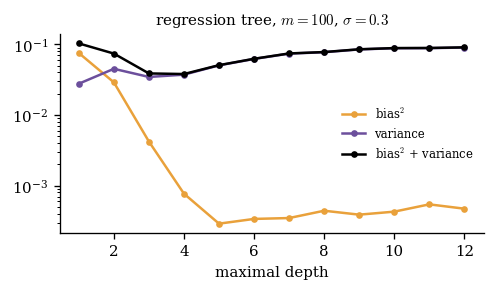

In [5]:
show_figure("tp2_biasvar")

In [6]:
show_table("p1_biasvar")

| depth $D$ | bias$^2$ | variance | bias$^2$+variance+$\sigma^2$ |
|:---:|:---:|:---:|:---:|
| 1 | 0.0754 | 0.0277 | 0.1931 |
| 2 | 0.0290 | 0.0451 | 0.1640 |
| 3 | 0.0042 | 0.0346 | 0.1288 |
| 4 | 0.0008 | 0.0372 | 0.1280 |
| 5 | 0.0003 | 0.0505 | 0.1407 |
| 6 | 0.0003 | 0.0622 | 0.1525 |
| 7 | 0.0003 | 0.0740 | 0.1644 |
| 8 | 0.0004 | 0.0774 | 0.1678 |
| 9 | 0.0004 | 0.0848 | 0.1752 |
| 10 | 0.0004 | 0.0881 | 0.1786 |
| 11 | 0.0005 | 0.0884 | 0.1789 |
| 12 | 0.0005 | 0.0902 | 0.1807 |

For a new point $(x,y)$, $y=f(x)+\varepsilon$ with $\varepsilon$ independent of the training set, hence $\mathbb{E}[(y-\hat f(x))^2]=\sigma^2+(\mathbb{E}\hat f(x)-f(x))^2+\mathrm{Var}\,\hat f(x)$, the cross terms having zero mean. A tree of depth $D$ is piecewise constant with at most $2^D$ pieces: for $D\leq2$ it cannot follow the sine (large bias); from $D=3$ the bias is negligible, but the variance increases with the depth, as the leaves contain fewer points. A full tree has an almost zero bias and a variance close to $\sigma^2$: the ideal candidate for an averaging method.

## Part 2 – Bagging from scratch (Section 10.2)

1.  Show that a bootstrap sample of size $m$ contains on average a proportion $1-(1-\frac1m)^m\approx1-e^{-1}\approx63.2\%$ of distinct examples.\
    Check it numerically for $m=537$.

2.  Write `bagging(Xtr, ytr, Xte, B, rng)` which learns $B$ fully grown trees, each on a bootstrap sample, and returns the $B\times n_{\text{test}}$ matrix of their predictions.\
    On `wdbc`, `pima` and `spambase` ($B=200$, $3$ splits), compute the test error of one full tree learned on the whole training set, the mean test error of a bagged tree, and the test error of the vote (ties: majority class).\
    Plot the error of the vote of the first $B$ trees as a function of $B$.

3.  **Out-of-bag error.** Each training example is *out of bag* for about $37\%$ of the trees.\
    Predict each training example by the vote of these trees only, and compute the out-of-bag (OOB) error.\
    Compare it with the test error.\
    Why is it a valid estimate of the risk of the vote, without any validation set?

4.  Compare with `BaggingClassifier(DecisionTreeClassifier(), n_estimators=200)`.

5.  Does the vote overfit when $B$ increases?\
    How many trees are needed?

In [7]:
def bagging(Xtr, ytr, Xte, B, rng, base=None):
    """B models learned on bootstrap samples. Returns the B x n_test matrix of predictions on Xte, and the sum and
    number of out-of-bag votes for each training example."""
    base = base or (lambda r: DecisionTreeClassifier(random_state=r))
    m = len(ytr); V = np.empty((B, len(Xte)), dtype=int); oob_sum = np.zeros(m); oob_cnt = np.zeros(m)
    for b in range(B):
        idx = rng.randint(0, m, m); oob = np.ones(m, bool); oob[idx] = False
        h = base(b).fit(Xtr[idx], ytr[idx]); V[b] = h.predict(Xte)
        if oob.any():
            oob_sum[oob] += h.predict(Xtr[oob]); oob_cnt[oob] += 1
    return V, oob_sum, oob_cnt


def vote(S, tie):
    return np.where(S > 0, 1, np.where(S < 0, -1, tie))


def part2():
    print("Part 2")
    rows = []; curves = {}
    for name in ["wdbc", "pima", "spambase"]:
        R = []
        for seed in range(3):
            Xtr, Xte, ytr, yte = split(name, seed); tie = 1 if np.mean(ytr == 1) >= 0.5 else -1
            rng = np.random.RandomState(seed)
            single = np.mean(DecisionTreeClassifier(random_state=0).fit(Xtr, ytr).predict(Xte) != yte)
            V, os_, oc = bagging(Xtr, ytr, Xte, 200, rng)
            errB = np.mean(vote(np.cumsum(V, 0), tie) != yte[None, :], axis=1)
            trees = np.mean(V != yte[None, :], axis=1)
            ok = oc > 0; oob = np.mean(vote(os_[ok], tie) != ytr[ok])
            sk = BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=seed, n_jobs=-1).fit(Xtr, ytr)
            R.append((single, trees.mean(), errB[-1], oob, np.mean(sk.predict(Xte) != yte)))
            if seed == 0:
                curves[name] = (single, errB, trees.mean())
        M = np.mean(R, 0)
        rows.append(f"{name} & {M[0]:.3f} & {M[1]:.3f} & {M[2]:.3f} & {M[3]:.3f} & {M[4]:.3f}")
    keep_table("p2_bagging", rows)
    fig, axes = plt.subplots(1, 3, figsize=(7.8, 2.4))
    for ax, (name, (single, eb, gb)) in zip(axes, curves.items()):
        Bs = np.arange(1, len(eb) + 1)
        ax.axhline(single, color=GREY, ls=":", lw=1, label="one full tree")
        ax.plot(Bs, eb, color=C1, label="vote of the first $B$ trees")
        ax.axhline(gb, color=C2, ls="--", lw=0.9, label="mean error of a bagged tree")
        ax.set_xscale("log"); ax.set_xlabel("number of trees $B$"); ax.set_title(name, fontsize=9)
    axes[0].set_ylabel("test error"); axes[0].legend(fontsize=6.5)
    fig.tight_layout(); keep_figure(fig, "tp2_bagging")
    # fraction of distinct examples in a bootstrap sample
    rng = np.random.RandomState(0); m = 537
    frac = np.mean([len(np.unique(rng.randint(0, m, m))) / m for _ in range(1000)])
    keep_table("p2_bootstrap", [f"{m} & {frac:.4f} & {1 - (1 - 1 / m) ** m:.4f} & {1 - np.exp(-1):.4f}"])

In [8]:
part2()

Part 2


### Solution

**1.** A given example is missed by one draw with probability $1-\frac1m$, hence by the $m$ independent draws with probability $(1-\frac1m)^m=e^{m\ln(1-1/m)}\to e^{-1}$. By linearity, the expected proportion of distinct examples is $1-(1-\frac1m)^m$. For $m=537$:

In [9]:
show_table("p2_bootstrap")

| $m$ | simulated proportion | $1-(1-\frac1m)^m$ | $1-e^{-1}$ |
|:---:|:---:|:---:|:---:|
| 537 | 0.6321 | 0.6325 | 0.6321 |

**2 and 4.** Averages over $3$ splits:

In [10]:
show_table("p2_bagging")

| data | one full tree | mean bagged tree | vote ($B=200$) | OOB error | `BaggingClassifier` |
|:---:|:---:|:---:|:---:|:---:|:---:|
| wdbc | 0.068 | 0.083 | 0.062 | 0.039 | 0.060 |
| pima | 0.302 | 0.309 | 0.245 | 0.241 | 0.250 |
| spambase | 0.094 | 0.103 | 0.061 | 0.057 | 0.062 |

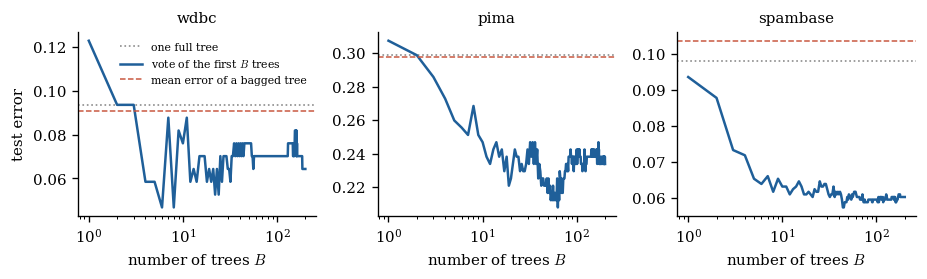

In [11]:
show_figure("tp2_bagging")

Each bagged tree is a bit worse than a tree learned on the whole training set (it only sees $63\%$ of the distinct examples), yet the vote is much better than both: $0.245$ against $0.302$ for one tree on `pima`, $0.061$ against $0.094$ on `spambase` (less so on `wdbc`: $0.062$ against $0.068$). Our implementation and `scikit-learn`'s give the same errors, up to the randomness of the bootstrap.

**3.** The trees for which $(x_i,y_i)$ is out of bag did not see it: their vote on $x_i$ is a prediction on an unseen example, as for a test point. The OOB error is thus an (almost) unbiased estimate of the risk of a vote of about $0.37B$ trees, obtained for free, without setting data aside. It is close to the test error on `pima` and `spambase`; on `wdbc` it is smaller ($0.039$ against $0.062$), within the fluctuations of a test set of $171$ examples ($0.02$ is $4$ errors).

**5.** No: the error of the vote decreases and then stabilizes; adding trees only reduces the randomness of the vote, it does not make the model more complex (compare with boosting in TP 3). A few dozen trees capture most of the gain and $100$--$500$ trees are enough; $B$ is not a hyperparameter to tune, the larger the better (up to the computing time).

## Part 3 – What does bagging reduce? (Section 10.1)

1.  For the regression problem ($R=100$ training samples of size $100$), compare the squared bias and the variance of a single regression tree and of a bagged average of $50$ regression trees, for depths $2$, $4$ and unlimited.

2.  On `pima` and `spambase` ($3$ splits), compare the test error of a model and of the vote of $50$ bagged copies of it, for: a fully grown tree, a tree of depth $2$, $15$-NN and a logistic regression (both with standardization).\
    Which models benefit from bagging?\
    Explain.

In [12]:
def part3():
    print("Part 3")
    # (a) bias and variance of a bagged regression tree versus a single tree
    rng = np.random.RandomState(2); xs = (np.arange(200) + 0.5) / 200; R, m, sig = 100, 100, 0.3; rows = []
    for depth in [2, 4, None]:
        P1, PB = [], []
        for _ in range(R):
            x = rng.rand(m); yy = f_true(x) + sig * rng.randn(m)
            P1.append(DecisionTreeRegressor(max_depth=depth, random_state=0).fit(x[:, None], yy).predict(xs[:, None]))
            pb = np.zeros(len(xs))
            for b in range(50):
                idx = rng.randint(0, m, m)
                pb += DecisionTreeRegressor(max_depth=depth, random_state=b).fit(x[idx, None], yy[idx]).predict(xs[:, None]) / 50
            PB.append(pb)
        for lab, P in [("single tree", np.array(P1)), ("bagging, $B=50$", np.array(PB))]:
            b2 = np.mean((P.mean(0) - f_true(xs)) ** 2); v = np.mean(P.var(0))
            rows.append(f"{'full' if depth is None else depth} & {lab} & {b2:.4f} & {v:.4f} & {b2 + v + sig ** 2:.4f}")
    keep_table("p3_biasvar_bag", rows)
    # (b) bagging unstable versus stable classifiers
    models = {"full tree": lambda r: DecisionTreeClassifier(random_state=r),
              "tree of depth 2": lambda r: DecisionTreeClassifier(max_depth=2, random_state=r),
              "15-NN (standardized)": lambda r: make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
              "logistic regression": lambda r: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))}
    rows = []
    for lab, f in models.items():
        res = []
        for name in ["pima", "spambase"]:
            e1, eb = [], []
            for seed in range(3):
                Xtr, Xte, ytr, yte = split(name, seed); tie = 1 if np.mean(ytr == 1) >= 0.5 else -1
                e1.append(np.mean(f(0).fit(Xtr, ytr).predict(Xte) != yte))
                V, _, _ = bagging(Xtr, ytr, Xte, 50, np.random.RandomState(seed), f)
                eb.append(np.mean(vote(V.sum(0), tie) != yte))
            res += [np.mean(e1), np.mean(eb)]
        rows.append(f"{lab} & {res[0]:.3f} & {res[1]:.3f} & {res[2]:.3f} & {res[3]:.3f}")
    keep_table("p3_stable", rows)

In [13]:
part3()

Part 3


### Solution

**1.**

In [14]:
show_table("p3_biasvar_bag")

| depth | model | bias$^2$ | variance | bias$^2$+variance+$\sigma^2$ |
|:---:|:---:|:---:|:---:|:---:|
| 2 | single tree | 0.0307 | 0.0431 | 0.1638 |
| 2 | bagging, $B=50$ | 0.0273 | 0.0171 | 0.1343 |
| 4 | single tree | 0.0013 | 0.0387 | 0.1300 |
| 4 | bagging, $B=50$ | 0.0008 | 0.0206 | 0.1114 |
| full | single tree | 0.0010 | 0.0878 | 0.1789 |
| full | bagging, $B=50$ | 0.0006 | 0.0426 | 0.1332 |

Bagging leaves the bias almost unchanged (the average of trees has about the same expectation as one tree) and divides the variance by about $2$; for full trees, the expected MSE drops from $0.179$ to $0.133$, close to the best single tree of Part 1 ($0.128$ at depth $4$) without tuning the depth, and bagged trees of depth $4$ reach $0.111$, the best of all. With depth $2$ the bias remains: bagging cannot repair an underfitting model.

**2.** Test errors (averages over $3$ splits):

In [15]:
show_table("p3_stable")

| base model | `pima` – alone | `pima` – bagged | `spambase` – alone | `spambase` – bagged |
|:---:|:---:|:---:|:---:|:---:|
| full tree | 0.302 | 0.257 | 0.094 | 0.063 |
| tree of depth 2 | 0.250 | 0.261 | 0.151 | 0.134 |
| 15-NN (standardized) | 0.260 | 0.260 | 0.099 | 0.099 |
| logistic regression | 0.228 | 0.229 | 0.076 | 0.073 |

Bagging helps a lot for fully grown trees (low bias, high variance), little or not at all for stable models: $15$-NN and the logistic regression hardly change when a third of the examples are replaced, so their bootstrap copies make the same predictions and their vote is the model itself. A tree of depth $2$ is both biased and fairly stable: bagging helps it little (slightly worse on `pima`, better on `spambase`, $0.151\to0.134$), and it stays far behind bagged full trees because its bias remains. Rule: bag low-bias, high-variance models.

## Part 4 – Random forests: decorrelating the trees (Sections 10.2, 12 and 15.4)

A random forest is bagging in which, at each node of each tree, the best split is searched among $m_{\text{try}}$ features drawn at random instead of all the $d$ features (`DecisionTreeClassifier(max_features=mtry)`); $m_{\text{try}}=d$ is bagging.

**Notation of Part IV.** The vote of $B$ trees with equal weights is the majority vote $B_Q$ of the uniform distribution $Q$ on the trees (Section 12.2). For an example $(x,y)$, $W_Q(x,y)$ is the proportion of trees that err on it; the vote errs when $W_Q\geq\frac12$. The mean error of the trees is the *Gibbs risk* $\widehat{R}_S(G_Q)=\widehat{\mathbb{E}}[W_Q]$ (Definition 12.1). For two trees $h,h'$ drawn independently from $Q$ (possibly the same one), the *joint error* $\hat e(Q)$ is the probability that both err and the *disagreement* $\hat d(Q)$ the probability that they predict differently (Definition 15.4).

1.  For $m_{\text{try}}\in\{1,2,3,5,8\}$ on `pima` and $\{1,3,7,15,30,57\}$ on `spambase`, learn forests of $100$ trees and compute (a) the mean test error of one tree, (b) the mean *disagreement* between two distinct trees (the proportion of test points on which they predict differently, averaged over the pairs), (c) the test error of the vote.\
    Plot the three quantities against $m_{\text{try}}$ and comment.

2.  Show that, with $v(x)=\frac1B\sum_bh_b(x)$, the mean disagreement over the $B(B-1)$ ordered pairs of distinct trees is $\frac{B}{B-1}\,\widehat{\mathbb{E}}_x\big[\frac{1-v(x)^2}{2}\big]$.\
    Show that the disagreement $\hat d(Q)$ of Part IV, which averages over all the $B^2$ ordered pairs (including $h=h'$), is $\widehat{\mathbb{E}}_x\big[\frac{1-v(x)^2}{2}\big]=\widehat{\mathbb{E}}\big[2W_Q(1-W_Q)\big]$, that $\hat e(Q)=\widehat{\mathbb{E}}[W_Q^2]$, and deduce the identity $\widehat{R}_S(G_Q)=\hat e(Q)+\frac12\hat d(Q)$ (Proposition 15.5).

3.  On the four datasets, compare a single tree whose depth is tuned by $5$-fold cross-validation (TP 1) with `RandomForestClassifier(500, max_features="sqrt", oob_score=True)`.\
    Compare the OOB error of the forest with its test error.

4.  **The puzzling experiment of Section 12.1.** On the `digits` dataset of `scikit-learn` (task: is the digit smaller than $5$?), split the data with `train_test_split(X, y, test_size=0.3, random_state=0)` ($1257$ training and $540$ test digits) and grow $100$ trees, each on a bootstrap sample of *half* the size of the training set, with `max_features="sqrt"`.\
    Plot, as a function of $n$, the test error of the vote of the first $n$ trees, their Gibbs risk and their disagreement; plot the histogram of the test errors of the $100$ trees.\
    Compute $\hat e(Q)$ and $\hat d(Q)$ for the $100$ trees on the test set and check the identity of question 2.\
    Why is the vote so much better than its trees?

In [16]:
def mean_disagreement(V):
    B = len(V); v = V.mean(0)
    return float(np.mean((1 - v ** 2) / 2) * B / (B - 1))


def part4():
    print("Part 4")
    rows = []; plot = {}
    for name, grid in [("pima", [1, 2, 3, 5, 8]), ("spambase", [1, 3, 7, 15, 30, 57])]:
        d = load(name)[0].shape[1]
        for mf in grid:
            R = []
            for seed in range(3):
                Xtr, Xte, ytr, yte = split(name, seed); tie = 1 if np.mean(ytr == 1) >= 0.5 else -1
                V, _, _ = bagging(Xtr, ytr, Xte, 100, np.random.RandomState(seed),
                                  lambda r: DecisionTreeClassifier(max_features=None if mf == d else mf, random_state=r))
                R.append((np.mean(V != yte[None, :]), mean_disagreement(V), np.mean(vote(V.sum(0), tie) != yte)))
            M = np.mean(R, 0); plot.setdefault(name, []).append((mf, *M))
            rows.append(f"{name} & {mf}{' (bagging)' if mf == d else ''} & {M[0]:.3f} & {M[1]:.3f} & {M[2]:.3f}")
    keep_table("p4_rf", rows)
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.4))
    for ax, (name, L) in zip(axes, plot.items()):
        L = np.array(L)
        ax.plot(L[:, 0], L[:, 1], "o-", ms=3, color=C2, label="mean error of one tree")
        ax.plot(L[:, 0], L[:, 2], "o-", ms=3, color=C4, label="mean disagreement of two trees")
        ax.plot(L[:, 0], L[:, 3], "o-", ms=3, color=C1, label="error of the vote")
        ax.set_xlabel("number of features drawn at each node ($m_{\\mathrm{try}}$)"); ax.set_title(name, fontsize=9)
    axes[0].legend(fontsize=7)
    fig.tight_layout(); keep_figure(fig, "tp2_rf")
    # scikit-learn's random forest, its OOB error, and a comparison with a tuned single tree
    rows = []
    for name in ["wdbc", "pima", "australian", "spambase"]:
        R = []
        for seed in range(3):
            Xtr, Xte, ytr, yte = split(name, seed)
            rf = RandomForestClassifier(500, max_features="sqrt", oob_score=True, random_state=seed, n_jobs=-1).fit(Xtr, ytr)
            depth = max([1, 2, 3, 4, 6, 8, None], key=lambda dd: cross_val_score(DecisionTreeClassifier(max_depth=dd, random_state=0), Xtr, ytr,
                                                                                    cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean())
            tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xtr, ytr)
            R.append((np.mean(tree.predict(Xte) != yte), 1 - rf.oob_score_, np.mean(rf.predict(Xte) != yte)))
        M = np.mean(R, 0); rows.append(f"{name} & {M[0]:.3f} & {M[1]:.3f} & {M[2]:.3f}")
    keep_table("p4_sklearn", rows)

In [17]:
part4()

Part 4


### Solution

**1.** Averages over $3$ splits:

In [18]:
show_table("p4_rf")

| data | $m_{\text{try}}$ | mean error of a tree | mean disagreement | error of the vote |
|:---:|:---:|:---:|:---:|:---:|
| pima | 1 | 0.334 | 0.336 | 0.232 |
| pima | 2 | 0.317 | 0.311 | 0.238 |
| pima | 3 | 0.313 | 0.300 | 0.238 |
| pima | 5 | 0.311 | 0.290 | 0.245 |
| pima | 8 (bagging) | 0.310 | 0.285 | 0.248 |
| spambase | 1 | 0.129 | 0.173 | 0.048 |
| spambase | 3 | 0.120 | 0.158 | 0.046 |
| spambase | 7 | 0.113 | 0.143 | 0.050 |
| spambase | 15 | 0.107 | 0.130 | 0.055 |
| spambase | 30 | 0.105 | 0.121 | 0.057 |
| spambase | 57 (bagging) | 0.103 | 0.113 | 0.061 |

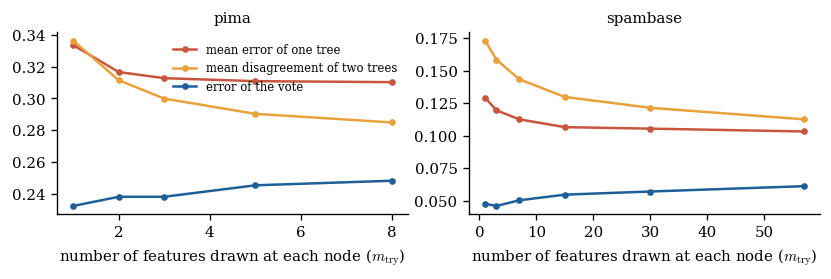

In [19]:
show_figure("tp2_rf")

When $m_{\text{try}}$ decreases, each tree gets worse (on `spambase`, from $0.103$ with bagging to $0.129$ with one feature per node) but the trees become more *diverse*: their disagreement increases from $0.113$ to $0.173$. The error of the vote results from these two opposite effects, and here diversity wins: the vote improves from $0.061$ (bagging) to $0.046$ ($m_{\text{try}}=3$) on `spambase`, and from $0.248$ to $0.232$ on `pima`. The default $m_{\text{try}}=\lfloor\sqrt d\rfloor$ ($7$ and $2$) is a good compromise. This "accuracy versus diversity" trade-off is exactly what the PAC-Bayesian bounds for majority votes of TP 5 quantify.

**2.** For $\pm1$ predictions, $\mathbb{1}\left[h_b(x)\neq h_{b'}(x)\right]=\frac{1-h_b(x)h_{b'}(x)}2$, and $\sum_{b\neq b'}h_bh_{b'}=\big(\sum_bh_b\big)^2-B=B^2v^2-B$. The mean disagreement at $x$ is thus $\frac{1}{B(B-1)}\cdot\frac{B(B-1)-(B^2v^2-B)}{2}=\frac{B}{B-1}\cdot\frac{1-v^2}{2}$; average over the test points. If the $B^2$ ordered pairs are all counted, the pairs $h=h'$ (which never disagree) add $B$ zeros, and the mean becomes $\frac{B(B-1)}{B^2}\cdot\frac{B}{B-1}\widehat{\mathbb{E}}\big[\frac{1-v^2}2\big]=\widehat{\mathbb{E}}\big[\frac{1-v^2}2\big]$. With $v=y(1-2W_Q)$, $\frac{1-v^2}{2}=2W_Q(1-W_Q)$. Two trees drawn independently from $Q$ both err on $(x,y)$ with probability $W_Q^2$, hence $\hat e(Q)=\widehat{\mathbb{E}}[W_Q^2]$, and $W_Q=W_Q^2+W_Q(1-W_Q)$ gives $\widehat{R}_S(G_Q)=\hat e(Q)+\frac12\hat d(Q)$.

**3.** Averages over $3$ splits:

In [20]:
show_table("p4_sklearn")

| data | tuned single tree (test) | forest, OOB error | forest, test error |
|:---:|:---:|:---:|:---:|
| wdbc | 0.086 | 0.031 | 0.057 |
| pima | 0.261 | 0.238 | 0.235 |
| australian | 0.153 | 0.131 | 0.143 |
| spambase | 0.087 | 0.048 | 0.050 |

The forest is better than the best single tree on every dataset, much better on `wdbc` and `spambase` (on `spambase`, $0.050$ against $0.087$), with almost no tuning. Its OOB error is a reliable estimate of its test error (differences from $0$ to $0.03$, of the order of the fluctuations of the test sets), and it can replace cross-validation to tune $m_{\text{try}}$ or the size of the leaves.

**4.** The forest of the running example of Part IV, reproduced:

In [21]:
def puzzling_forest(seed=0, n_trees=100):
    """The forest of the running example of Part IV of the notes (Section 12.1): digits (< 5 or not),
    1257 training / 540 test digits, 100 trees, each learned on a bootstrap sample of half the size of
    the training set, sqrt(d) features drawn at each node."""
    from sklearn.datasets import load_digits
    X, y = load_digits(return_X_y=True); y = np.where(y >= 5, 1, -1)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0)
    rng = np.random.RandomState(seed); m = len(ytr); V = []
    for t in range(n_trees):
        idx = rng.randint(0, m, m // 2)
        tree = DecisionTreeClassifier(max_features="sqrt", random_state=rng.randint(1 << 30)).fit(Xtr[idx], ytr[idx])
        V.append(tree.predict(Xte))
    return np.array(V), yte


def part4_digits():
    print("Part 4, question 4")
    V, yte = puzzling_forest(); E = (V != yte[None, :]).astype(float); B = len(V)
    ns = np.arange(1, B + 1); vote_err, gibbs, dis = [], [], []
    for n in ns:
        W = E[:n].mean(0)                                    # W_Q(x, y) for the uniform posterior on the first n trees
        S = V[:n].sum(0); vote_err.append(np.mean(yte * S <= 0))       # ties counted as errors (W_Q >= 1/2)
        gibbs.append(W.mean()); dis.append(np.mean(2 * W * (1 - W)))   # d = E[(1 - v^2)/2] = E[2 W (1 - W)]
    W = E.mean(0); g, e = W.mean(), np.mean(W ** 2); d = np.mean(2 * W * (1 - W))
    errs = E.mean(1)
    keep_table("p4_digits", [f"{vote_err[-1]:.3f} & {g:.3f} & {errs.min():.3f} -- {errs.max():.3f} & {e:.3f} & {d:.3f} & {e + d / 2:.3f}"])
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.5))
    ax = axes[0]
    ax.plot(ns, vote_err, color=C1, label="test error of the vote")
    ax.plot(ns, gibbs, color=C2, label="Gibbs risk (mean error of a tree)")
    ax.plot(ns, dis, color=C4, ls="--", label="disagreement $\\hat d(Q)$")
    ax.set_xlabel("number of trees $n$"); ax.legend(fontsize=7); ax.set_ylim(0, 0.45)
    ax = axes[1]
    ax.hist(errs, bins=15, color=C2, alpha=0.7, label="test errors of the 100 trees")
    ax.axvline(vote_err[-1], color=C1, lw=2, label="test error of the vote")
    ax.set_xlabel("test error"); ax.legend(fontsize=7)
    fig.tight_layout(); keep_figure(fig, "tp2_digits")


In [22]:
part4_digits()

Part 4, question 4


In [23]:
show_table("p4_digits")

| vote (test) | Gibbs risk $\widehat{R}(G_Q)$ | errors of the trees | joint error $\hat e(Q)$ | disagreement $\hat d(Q)$ | $\hat e+\hat d/2$ |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 0.044 | 0.190 | 0.139 – 0.252 | 0.057 | 0.266 | 0.190 |

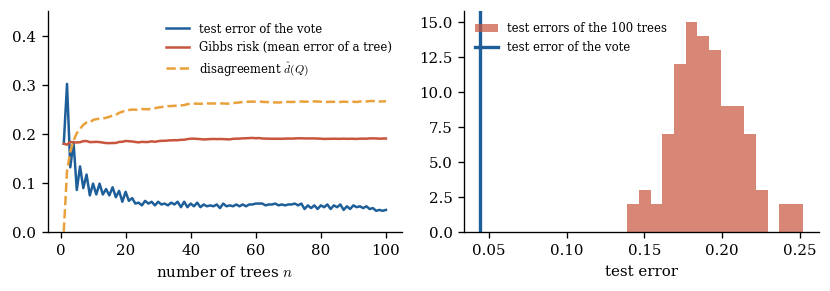

In [24]:
show_figure("tp2_digits")

We recover the numbers of Section 12.1: the trees err on $14\%$ to $25\%$ of the test digits ($19\%$ on average: this is the Gibbs risk), and their vote on only $4.4\%$, three times less than the *best* tree. The identity of question 2 holds exactly ($0.057+0.266/2=0.190$). Two trees drawn at random disagree on more than a quarter of the digits but both err on only $5.7\%$ of them: the errors of the trees are spread over different digits, so on most digits a large majority of trees is right ($W_Q<\frac12$). The vote improves quickly with the first $20$ trees and then stabilizes, while the Gibbs risk does not change: adding trees does not make them better, it makes the vote more stable. The joint error and the disagreement are the second-order quantities with which Section 15 (and TP 5) explains and certifies such votes: the tandem bound gives $4\hat e(Q)\approx0.23$, while the first-order bound $2\widehat{R}(G_Q)\approx0.38$ ignores the diversity.

## Part 5 – Going further $(\star)$

1.  **Variance of an average.** Let $Z_1,\dots,Z_B$ be identically distributed with variance $\sigma^2$ and pairwise correlation $\rho\geq0$.\
    Show that $\mathrm{Var}\big(\frac1B\sum_bZ_b\big)=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2$.\
    What does this formula say about bagging when $B\to\infty$, and about random forests?

2.  Check it numerically: on `pima`, at $40$ fixed test points, compute the average of the predictions ($\pm1$) of $B$ bagged full trees, for $60$ training sets (random halves of the training set), and estimate its variance for $B\in\{1,5,25,100\}$.\
    Estimate $\rho$ from $B=1$ and $B=100$ and compare the formula with the other values.

3.  If $B$ trees erred *independently* with probability $r<\frac12$ on every point, what would happen to the error of the vote when $B\to\infty$ (Condorcet's jury theorem, Proposition 15.3)?\
    Why is this not what we observe?

In [25]:
def part5():
    print("Part 5")
    rng = np.random.RandomState(7)
    Xtr, Xte, ytr, yte = split("pima", 0); Xq = Xte[:40]; rows = []
    for B in [1, 5, 25, 100]:
        avg = []
        for r in range(60):
            sub = rng.choice(len(ytr), len(ytr) // 2, replace=False); Xs, ys = Xtr[sub], ytr[sub]
            avg.append(np.mean([DecisionTreeClassifier(random_state=b).fit(Xs[i], ys[i]).predict(Xq)
                                for b, i in enumerate([rng.randint(0, len(ys), len(ys)) for _ in range(B)])], 0))
        rows.append((B, np.mean(np.var(np.array(avg), 0))))
    one = rows[0][1]; v100 = rows[-1][1]; rho = (v100 - one / 100) / (one - one / 100)
    out = [f"{B} & {v:.4f} & {rho * one + (1 - rho) * one / B:.4f}" for B, v in rows]
    out.append(f"--- $\\hat\\rho$ & \\multicolumn{{2}}{{c}}{{{rho:.3f}}}")
    keep_table("p5_bagvar", out)

In [26]:
part5()

Part 5


### Solution

**1.** $\mathrm{Var}\big(\frac1B\sum_bZ_b\big)=\frac1{B^2}\Big(\sum_b\mathrm{Var}Z_b+\sum_{b\neq b'}\mathrm{Cov}(Z_b,Z_{b'})\Big)
=\frac1{B^2}\big(B\sigma^2+B(B-1)\rho\sigma^2\big)=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2$. When $B\to\infty$ the second term vanishes but $\rho\sigma^2$ remains: bagging removes the variance due to the bootstrap, not the part due to the training set, which makes all the trees correlated. Random forests lower $\rho$ by randomizing the features, at the price of a slightly larger $\sigma^2$ and bias (Part 4).

**2.** Measured variance of the average of $B$ trees, and value predicted with $\sigma^2$ measured for $B=1$ and $\hat\rho$ fitted on $B=100$:

In [27]:
show_table("p5_bagvar")

| $B$ | measured variance | $\hat\rho\sigma^2+(1-\hat\rho)\sigma^2/B$ |
|:---:|:---:|:---:|
| 1 | 0.5952 | 0.5952 |
| 5 | 0.1529 | 0.1496 |
| 25 | 0.0650 | 0.0605 |
| 100 | 0.0438 | 0.0438 |
| $\hat\rho$ | 0.064 |  |

The formula, with a single fitted parameter, reproduces the intermediate values, and the variance is divided by more than $10$. (Our training sets are random halves of a fixed pool and share half of their points: $\hat\rho$ underestimates the correlation obtained with independent training sets.)

**3.** The number of erring trees would follow $\mathcal B(B,r)$, and by Hoeffding's inequality $\mathbb{P}(\text{vote errs})\leq e^{-2B(1/2-r)^2}\to0$ (Condorcet's jury theorem, Proposition 15.3). In practice the trees are learned on the same data and err together on the difficult points (noisy labels, ambiguous inputs): their errors are positively correlated, and the error of the vote stabilizes at a positive value. Measuring this correlation through the disagreement or the joint error of pairs of voters is the starting point of TP 5.